# NLP Sentiment Analysis — Task F

## AI Powered E-Commerce Customer Intelligence System

This notebook builds the required customer review sentiment classifier using the SQLite `reviews` table.

### Hackathon requirements
- Remove or handle unusable review records.
- Create labels: rating 1–2 = Negative, rating 3 = Neutral, rating 4–5 = Positive.
- Prepare the review text appropriately.
- Use TF-IDF text features.
- Train Logistic Regression.
- Report Accuracy, Precision, Recall and F1-score.
- State one limitation of the review dataset or sentiment-labeling approach.
- Save the trained sentiment pipeline for use by Streamlit.


## 1. Imports and configuration


In [1]:
import sqlite3
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

import joblib

pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')


## 2. Locate and load the SQLite database


In [2]:
NOTEBOOK_DIR = Path.cwd()

possible_paths = [
    NOTEBOOK_DIR / 'ecommerce_hackathon.db',
    NOTEBOOK_DIR.parent / 'ecommerce_hackathon.db',
    NOTEBOOK_DIR.parent.parent / 'ecommerce_hackathon.db',
]

DB_PATH = next((p for p in possible_paths if p.exists()), None)

if DB_PATH is None:
    raise FileNotFoundError(
        'ecommerce_hackathon.db was not found. Put the database in the notebook folder '
        'or one/two folders above it.'
    )

print('Database:', DB_PATH.resolve())

conn = sqlite3.connect(DB_PATH)
reviews = pd.read_sql_query('SELECT * FROM reviews;', conn)
conn.close()

print('Reviews shape:', reviews.shape)
print('Columns:')
print(reviews.columns.tolist())

display(reviews.head())


Database: C:\Users\IQRA TRADERS\Desktop\hackaton\hackaton\ecommerce_hackathon.db
Reviews shape: (26000, 6)
Columns:
['review_id', 'customer_id', 'product_id', 'review_date', 'rating', 'review_text']


,review_id,customer_id,product_id,review_date,rating,review_text
0,1,7210,787,2026-07-28,4,"I would buy this again, item feels durable. Re..."
1,2,5566,765,2026-05-16,5,"Very satisfied, seller description was accurat..."
2,3,6106,743,2025-10-21,4,"Very satisfied, quality feels premium. Good va..."
3,4,2735,90,2026-03-25,4,"Product arrived in great condition, quality fe..."
4,5,2124,197,2026-02-23,4,"Good experience overall, packing was neat. Wil..."


## 3. Inspect review data quality

The hackathon database is intentionally raw, so we first inspect missing values, duplicate records, ratings and review text before modeling.


In [3]:
print('Missing values:')
display(reviews.isna().sum().to_frame('missing_count'))

print('\nDuplicate rows:', reviews.duplicated().sum())

print('\nRating distribution:')
display(reviews['rating'].value_counts(dropna=False).sort_index())

print('\nReview text length summary:')
text_lengths = reviews['review_text'].astype('string').str.len()
display(text_lengths.describe())

print('\nSample review records:')
display(reviews[['rating', 'review_text']].head(10))


Missing values:


,missing_count
review_id,0
customer_id,0
product_id,0
review_date,0
rating,0
review_text,48



Duplicate rows: 0

Rating distribution:


rating
0       11
1      577
2     1437
3     5473
4    10905
5     7583
6       14
Name: count, dtype: int64


Review text length summary:


count   25,952.0000
mean        74.0103
std         12.3184
min          0.0000
25%         65.0000
50%         73.0000
75%         81.0000
max        125.0000
Name: review_text, dtype: Float64


Sample review records:


,rating,review_text
0,4,"I would buy this again, item feels durable. Re..."
1,5,"Very satisfied, seller description was accurat..."
2,4,"Very satisfied, quality feels premium. Good va..."
3,4,"Product arrived in great condition, quality fe..."
4,4,"Good experience overall, packing was neat. Wil..."
5,1,"Very disappointed, item stopped working quickl..."
6,3,"Decent but could be better, support response w..."
7,4,"Quality is better than expected, works exactly..."
8,3,"Product is usable, some details were different..."
9,2,"Would not recommend, product had scratches. On..."


## 4. Clean unusable review records

For sentiment classification, a record needs:
- a valid rating from 1 to 5;
- usable non-empty review text.

We do not delete records merely because they are unusual. We remove only records that cannot provide the required target or text input.


In [4]:
reviews_clean = reviews.copy()

# Convert rating to numeric
reviews_clean['rating'] = pd.to_numeric(
    reviews_clean['rating'], errors='coerce'
)

# Convert review text to string and normalize missing values
reviews_clean['review_text'] = reviews_clean['review_text'].astype('string')
reviews_clean['review_text'] = reviews_clean['review_text'].str.strip()

before_count = len(reviews_clean)

reviews_clean = reviews_clean[
    reviews_clean['rating'].between(1, 5, inclusive='both')
].copy()

reviews_clean = reviews_clean[
    reviews_clean['review_text'].notna() &
    (reviews_clean['review_text'].str.len() > 0)
].copy()

reviews_clean = reviews_clean.drop_duplicates(
    subset=['review_id'] if 'review_id' in reviews_clean.columns else ['rating', 'review_text']
).copy()

after_count = len(reviews_clean)

print('Records before cleaning:', before_count)
print('Records after cleaning:', after_count)
print('Records removed:', before_count - after_count)


Records before cleaning: 26000
Records after cleaning: 25885
Records removed: 115


## 5. Create sentiment labels

The labels follow the exact hackathon definition:

- Rating **1–2** → **Negative**
- Rating **3** → **Neutral**
- Rating **4–5** → **Positive**


In [5]:
def rating_to_sentiment(rating):
    if rating <= 2:
        return 'Negative'
    elif rating == 3:
        return 'Neutral'
    else:
        return 'Positive'

reviews_clean['sentiment'] = reviews_clean['rating'].apply(
    rating_to_sentiment
)

print('Sentiment distribution:')
sentiment_counts = reviews_clean['sentiment'].value_counts()
display(sentiment_counts.to_frame('count'))

print('\nSentiment percentages:')
display(
    (reviews_clean['sentiment'].value_counts(normalize=True) * 100)
    .round(2)
    .to_frame('percentage')
)

display(reviews_clean[['rating', 'sentiment', 'review_text']].head(10))


Sentiment distribution:


,count
sentiment,
Positive,18421
Neutral,5458
Negative,2006



Sentiment percentages:


,percentage
sentiment,
Positive,71.1600
Neutral,21.0900
Negative,7.7500


,rating,sentiment,review_text
0,4,Positive,"I would buy this again, item feels durable. Re..."
1,5,Positive,"Very satisfied, seller description was accurat..."
2,4,Positive,"Very satisfied, quality feels premium. Good va..."
3,4,Positive,"Product arrived in great condition, quality fe..."
4,4,Positive,"Good experience overall, packing was neat. Wil..."
5,1,Negative,"Very disappointed, item stopped working quickl..."
6,3,Neutral,"Decent but could be better, support response w..."
7,4,Positive,"Quality is better than expected, works exactly..."
8,3,Neutral,"Product is usable, some details were different..."
9,2,Negative,"Would not recommend, product had scratches. On..."


## 6. Prepare review text

The text preparation is intentionally conservative. We lowercase text, remove URLs, remove non-letter/non-number characters, normalize whitespace, and keep the resulting words for TF-IDF.

TF-IDF will perform the numerical text representation.


In [6]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    text = re.sub(r'[^a-z0-9\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

reviews_clean['clean_text'] = reviews_clean['review_text'].apply(clean_text)

# Remove records that become empty after cleaning
reviews_clean = reviews_clean[
    reviews_clean['clean_text'].str.len() > 0
].copy()

print('Usable records for modeling:', len(reviews_clean))
display(reviews_clean[['review_text', 'clean_text', 'sentiment']].head(10))


Usable records for modeling: 25885


,review_text,clean_text,sentiment
0,"I would buy this again, item feels durable. Re...",i would buy this again item feels durable reco...,Positive
1,"Very satisfied, seller description was accurat...",very satisfied seller description was accurate...,Positive
2,"Very satisfied, quality feels premium. Good va...",very satisfied quality feels premium good valu...,Positive
3,"Product arrived in great condition, quality fe...",product arrived in great condition quality fee...,Positive
4,"Good experience overall, packing was neat. Wil...",good experience overall packing was neat will ...,Positive
5,"Very disappointed, item stopped working quickl...",very disappointed item stopped working quickly...,Negative
6,"Decent but could be better, support response w...",decent but could be better support response wa...,Neutral
7,"Quality is better than expected, works exactly...",quality is better than expected works exactly ...,Positive
8,"Product is usable, some details were different...",product is usable some details were different ...,Neutral
9,"Would not recommend, product had scratches. On...",would not recommend product had scratches one ...,Negative


## 7. Prepare X and y and create a train/test split

We use stratification so the class proportions are approximately preserved in both training and testing data.


In [7]:
X = reviews_clean['clean_text']
y = reviews_clean['sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print('Training records:', len(X_train))
print('Testing records:', len(X_test))

print('\nTraining sentiment distribution:')
display(y_train.value_counts())

print('\nTesting sentiment distribution:')
display(y_test.value_counts())


Training records: 20708
Testing records: 5177

Training sentiment distribution:


sentiment
Positive    14737
Neutral      4366
Negative     1605
Name: count, dtype: int64


Testing sentiment distribution:


sentiment
Positive    3684
Neutral     1092
Negative     401
Name: count, dtype: int64

## 8. TF-IDF + Logistic Regression

The hackathon specifically requires TF-IDF and Logistic Regression.

The pipeline keeps the vectorizer and classifier together so the exact same text transformation is automatically used when the saved model is loaded in Streamlit.


In [8]:
sentiment_model = Pipeline([
    ('tfidf', TfidfVectorizer(
        lowercase=False,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True,
        max_features=30000
    )),
    ('classifier', LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        random_state=42
    ))
])

sentiment_model.fit(X_train, y_train)

print('TF-IDF + Logistic Regression model trained successfully.')


TF-IDF + Logistic Regression model trained successfully.


## 9. Evaluate the sentiment model

The required metrics are Accuracy, Precision, Recall and F1-score.


In [9]:
y_pred = sentiment_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, average='weighted', zero_division=0
)
recall = recall_score(
    y_test, y_pred, average='weighted', zero_division=0
)
f1 = f1_score(
    y_test, y_pred, average='weighted', zero_division=0
)

metrics_df = pd.DataFrame([{
    'Accuracy': accuracy,
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
}])

display(metrics_df)

print('Classification Report:')
print(
    classification_report(
        y_test,
        y_pred,
        digits=4,
        zero_division=0
    )
)


,Accuracy,Precision,Recall,F1-score
0,1.0000,1.0000,1.0000,1.0000


Classification Report:
              precision    recall  f1-score   support

    Negative     1.0000    1.0000    1.0000       401
     Neutral     1.0000    1.0000    1.0000      1092
    Positive     1.0000    1.0000    1.0000      3684

    accuracy                         1.0000      5177
   macro avg     1.0000    1.0000    1.0000      5177
weighted avg     1.0000    1.0000    1.0000      5177



## 10. Confusion Matrix


Confusion Matrix:
[[ 401    0    0]
 [   0 1092    0]
 [   0    0 3684]]


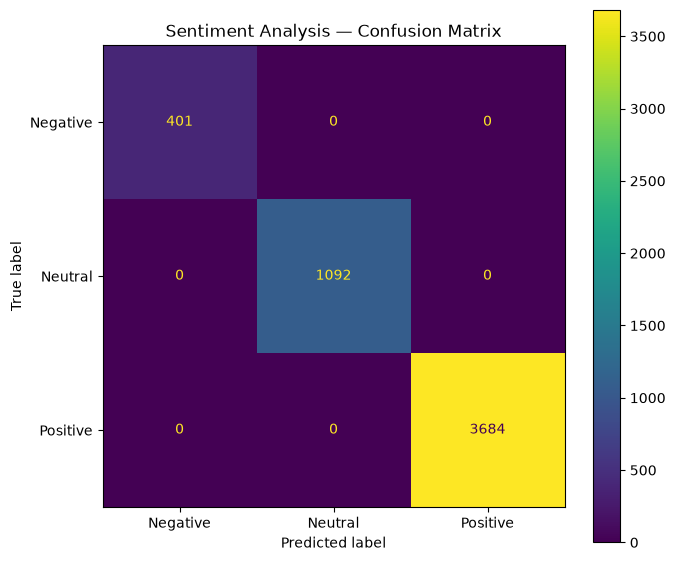

In [10]:
labels = ['Negative', 'Neutral', 'Positive']
cm = confusion_matrix(y_test, y_pred, labels=labels)

print('Confusion Matrix:')
print(cm)

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
).plot(ax=ax)
ax.set_title('Sentiment Analysis — Confusion Matrix')
plt.tight_layout()
plt.show()


## 11. Review sentiment examples

Check several real test examples to make sure the predictions are understandable and to identify common mistakes.


In [13]:
comparison = pd.DataFrame({
    'Review': X_test.values,
    'Actual': y_test.values,
    'Predicted': y_pred
})

display(comparison.head(20))


,Review,Actual,Predicted
0,very satisfied works exactly as expected satis...,Positive,Positive
1,i would buy this again customer support was he...,Positive,Positive
2,very satisfied item feels durable will order a...,Positive,Positive
3,delivery and product were both good delivery w...,Positive,Positive
4,nothing special delivery took a little longer ...,Neutral,Neutral
5,it does the job support response was slow migh...,Neutral,Neutral
6,worth the money item feels durable happy with ...,Positive,Positive
7,good experience overall size and color were co...,Positive,Positive
8,good experience overall item feels durable fiv...,Positive,Positive
9,item is acceptable support response was slow n...,Neutral,Neutral


## 12. Save the complete sentiment pipeline

The saved pipeline contains both TF-IDF and Logistic Regression, allowing Streamlit to pass raw review text directly to the model.


In [14]:
MODEL_DIR = Path.cwd() / 'models'
MODEL_DIR.mkdir(exist_ok=True)

sentiment_model_path = MODEL_DIR / 'sentiment_model.pkl'

joblib.dump(sentiment_model, sentiment_model_path)

print('Saved:', sentiment_model_path.resolve())
print('File exists:', sentiment_model_path.exists())


Saved: C:\Users\IQRA TRADERS\Desktop\hackaton\hackaton\models\sentiment_model.pkl
File exists: True


## 13. Reload the saved model and test it

This verifies that the model can be loaded independently, which is important before connecting it to Streamlit.


In [15]:
loaded_sentiment_model = joblib.load(sentiment_model_path)

test_text = "The product quality is excellent and I am very happy with my purchase."

test_prediction = loaded_sentiment_model.predict([clean_text(test_text)])[0]
test_probabilities = loaded_sentiment_model.predict_proba(
    [clean_text(test_text)]
)[0]

print('Test review:', test_text)
print('Predicted sentiment:', test_prediction)

print('\nClass probabilities:')
for class_name, probability in zip(
    loaded_sentiment_model.classes_,
    test_probabilities
):
    print(f'{class_name}: {probability:.4f}')


Test review: The product quality is excellent and I am very happy with my purchase.
Predicted sentiment: Positive

Class probabilities:
Negative: 0.0173
Neutral: 0.0104
Positive: 0.9723


## 14. Task F limitation

A key limitation is that the sentiment labels are created directly from star ratings rather than manually annotated sentiment. A 1–2 rating is treated as Negative, 3 as Neutral, and 4–5 as Positive, but the rating may not always capture the exact sentiment expressed in the written review. Therefore, the model may learn rating-related patterns that do not perfectly represent textual sentiment.


## Task F checklist

- [ ] Reviews loaded from SQLite
- [ ] Missing/unusable reviews handled
- [ ] Rating 1–2 → Negative
- [ ] Rating 3 → Neutral
- [ ] Rating 4–5 → Positive
- [ ] Text prepared
- [ ] TF-IDF used
- [ ] Logistic Regression trained
- [ ] Accuracy reported
- [ ] Precision reported
- [ ] Recall reported
- [ ] F1-score reported
- [ ] Confusion Matrix inspected
- [ ] Limitation documented
- [ ] `sentiment_model.pkl` saved
- [ ] Saved model successfully reloaded
